# Homework 3

This file contains the solutions to the computational problems in Homework 3 from MATH 5750 taught by Braxton Osting during the Fall 2026 semester.

This code is a mix between my own work, reference code released by Braxton Osting, and code generated by ChatGPT.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph, NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.linalg import eigh

Create concentric circles

In [4]:
n = 500

X, y_true = make_circles(n_samples=n, factor=0.45, noise=0.05, random_state=0)

Part (a) Run $k$-means on the concentric circles

In [ ]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
y_kmeans = kmeans.fit_predict(X)

ari_kmeans = adjusted_rand_score(y_true, y_kmeans)

Run spectral clustering on the concentric circles with $k_{nn}=10$ and $\epsilon$ equal to the median distance from a point to its 10th nearest neighbor.

In [9]:
nn = NearestNeighbors(n_neighbors=11)
nn.fit(X)

distances, indices = nn.kneighbors(X)

epsilon = np.median(distances[:, 10])

print("epsilon =", epsilon)

k_nn = 10

A = kneighbors_graph(
    X,
    n_neighbors=k_nn,
    mode="distance",
    include_self=False
)

A = A.maximum(A.T)

W = A.copy()
W.data = np.exp(-(W.data ** 2) / (2 * epsilon ** 2))

epsilon = 0.12010238417011855


Count connected components to answer question in the homework

In [10]:
n_components, component_labels = connected_components(
    W,
    directed=False
)

print("Number of connected components:", n_components)

Number of connected components: 2


Run spectral clustering with the $W$ matrix defined in the problem

In [12]:
spectral = SpectralClustering(n_clusters=2, affinity="precomputed", random_state=0, assign_labels="kmeans"
)

y_spectral = spectral.fit_predict(W)

ari_spectral = adjusted_rand_score(y_true, y_spectral)

print("k-means ARI:", ari_kmeans)
print("spectral clustering ARI:", ari_spectral)

k-means ARI: -0.001863710783495236
spectral clustering ARI: 1.0


c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Now compute sepctral clustering using $L_{sym} = I - D^{-1/2}WD^{-1/2}$

In [13]:
W_dense = W.toarray()

degrees = W_dense.sum(axis=1)
D_inv_sqrt = np.diag(1 / np.sqrt(degrees))

L_sym = np.eye(n) - D_inv_sqrt @ W_dense @ D_inv_sqrt

eigenvalues, eigenvectors = eigh(L_sym)

phi1 = D_inv_sqrt @ eigenvectors[:, 1]
phi2 = D_inv_sqrt @ eigenvectors[:, 2]

Create Figure 1 as follows: our panels side by side: the data colored by true label; the graph you built, with its edges drawn; the embedding, with $\phi_1$ and $\phi_2$ on the two axes; and the data colored by the clustering you obtained.

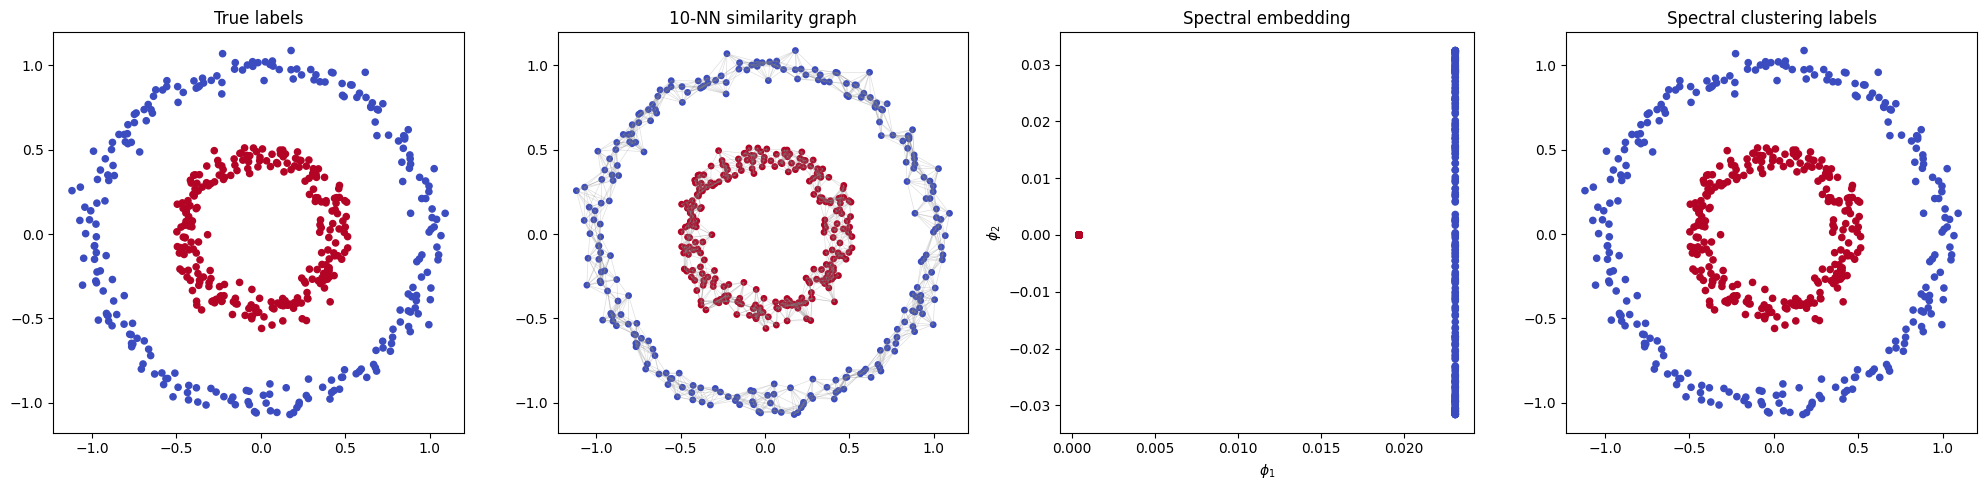

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Panel 1: true labels
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap="coolwarm", s=20)
axes[0].set_title("True labels")
axes[0].set_aspect("equal")

# Panel 2: k-NN graph
axes[1].scatter(X[:, 0], X[:, 1], c=y_true, cmap="coolwarm", s=15)

rows, cols = W.nonzero()
for i, j in zip(rows, cols):
    if i < j:
        axes[1].plot(
            [X[i, 0], X[j, 0]],
            [X[i, 1], X[j, 1]],
            color="gray",
            alpha=0.25,
            linewidth=0.5
        )

axes[1].set_title(f"{k_nn}-NN similarity graph")
axes[1].set_aspect("equal")

# Panel 3: spectral embedding
axes[2].scatter(phi1, phi2, c=y_true, cmap="coolwarm", s=20)
axes[2].set_xlabel(r"$\phi_1$")
axes[2].set_ylabel(r"$\phi_2$")
axes[2].set_title("Spectral embedding")

# Panel 4: spectral-clustering result in original plane
axes[3].scatter(X[:, 0], X[:, 1], c=y_spectral, cmap="coolwarm", s=20)
axes[3].set_title("Spectral clustering labels")
axes[3].set_aspect("equal")

plt.tight_layout()
plt.show()

Part (b) sweeps over different $k_{nn}$ and $\epsilon/\epsilon_0$ values

In [18]:
knn_values = [3, 5, 10, 20, 40, 80]
epsilon_ratios = [0.1, 0.25, 0.5, 1, 2, 4, 10]

ari_table = np.zeros((len(knn_values), len(epsilon_ratios)))

for i, k_nn in enumerate(knn_values):

    A = kneighbors_graph(X, n_neighbors=k_nn, mode="distance", include_self=False)

    A = A.maximum(A.T)

    for j, ratio in enumerate(epsilon_ratios):

        eps = ratio * epsilon

        W = A.copy()
        W.data = np.exp(-(W.data**2) / (2 * eps**2))

        spectral = SpectralClustering(n_clusters=2, affinity="precomputed", assign_labels="kmeans", eigen_solver="arpack", eigen_tol=1e-4, random_state=0)

        y_pred = spectral.fit_predict(W)

        ari_table[i, j] = adjusted_rand_score(y_true, y_pred)

c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph 

Create Figure 2 as follows: one table or heat map of the 6×7 ARI values, rows indexed by $k_{nn}$ and columns
by $\epsilon/\epsilon_0$

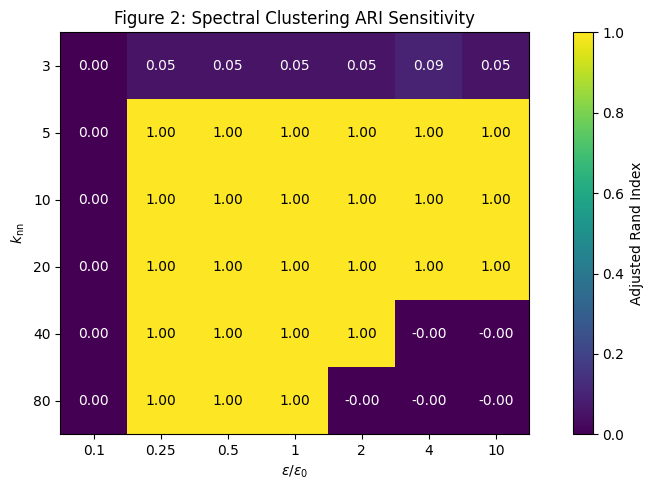

ARI table:
[[ 3.20651523e-05  5.30456073e-02  5.30456073e-02  5.30456073e-02
   5.30456073e-02  9.39177233e-02  5.30456073e-02]
 [ 3.20651523e-05  1.00000000e+00  1.00000000e+00  1.00000000e+00
   1.00000000e+00  1.00000000e+00  1.00000000e+00]
 [ 3.20651523e-05  1.00000000e+00  1.00000000e+00  1.00000000e+00
   1.00000000e+00  1.00000000e+00  1.00000000e+00]
 [ 3.20651523e-05  1.00000000e+00  1.00000000e+00  1.00000000e+00
   1.00000000e+00  1.00000000e+00  1.00000000e+00]
 [ 3.20651523e-05  1.00000000e+00  1.00000000e+00  1.00000000e+00
   1.00000000e+00 -1.42971722e-03 -1.42971722e-03]
 [ 3.20651523e-05  1.00000000e+00  1.00000000e+00  1.00000000e+00
  -2.00803213e-03 -1.94377485e-03 -2.00790336e-03]]


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(ari_table, cmap="viridis", vmin=0, vmax=1)

ax.set_xticks(range(len(epsilon_ratios)))
ax.set_xticklabels(epsilon_ratios)
ax.set_yticks(range(len(knn_values)))
ax.set_yticklabels(knn_values)

ax.set_xlabel(r"$\epsilon / \epsilon_0$")
ax.set_ylabel(r"$k_{\mathrm{nn}}$")
ax.set_title("Figure 2: Spectral Clustering ARI Sensitivity")

# Put the ARI value inside each heat-map square
for i in range(len(knn_values)):
    for j in range(len(epsilon_ratios)):
        color = "white" if ari_table[i, j] < 0.5 else "black"
        ax.text(
            j, i, f"{ari_table[i, j]:.2f}",
            ha="center", va="center", color=color
        )

plt.colorbar(im, ax=ax, label="Adjusted Rand Index")
plt.tight_layout()
plt.show()

# print("ARI table:")
# print(ari_table)

Part (c), now we will redo part (a) with a different dataset